# CSC 4110 – Machine Learning
## Group G9 – Task 9.2: Responsible AI and Model Card

**Dataset:** IBM HR Analytics Employee Attrition Dataset

**Objective:** Evaluate model fairness across Gender, MaritalStatus and age groups; check identifiers and data leakage; and document responsible use of the model.

**Deliverables:**
- `outputs/fairness.csv`
- `outputs/fairness.png`
- `report/model_card.md`
- `notebooks/G09_U9.2_responsible_ai.ipynb`

In [13]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [14]:
import os

project_path = "/content/drive/MyDrive/CSC4110_G09"

print("Project folder exists:", os.path.exists(project_path))
print("Data folder exists:", os.path.exists(project_path + "/data"))

if os.path.exists(project_path + "/data"):
    print(os.listdir(project_path + "/data"))

Project folder exists: True
Data folder exists: True
['WA_Fn-UseC_-HR-Employee-Attrition.csv', 'stage1_hr.csv', 'clean_hr.csv']


In [15]:
# Import libraries required for data preparation, modelling and evaluation
import pandas as pd
import numpy as np
import os
import joblib
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Set the project directory
project_path = "/content/drive/MyDrive/CSC4110_G09"

# Load the employee attrition dataset
data_path = os.path.join(
    project_path,
    "data",
    "WA_Fn-UseC_-HR-Employee-Attrition.csv"
)

df = pd.read_csv(data_path)

# Create folders for Task 9.2 deliverables
os.makedirs(os.path.join(project_path, "outputs"), exist_ok=True)
os.makedirs(os.path.join(project_path, "report"), exist_ok=True)

# Display dataset information
print("Dataset shape:", df.shape)
print("\nFirst five rows:")
display(df.head())

print("\nAttrition distribution:")
print(df["Attrition"].value_counts())

Dataset shape: (1470, 35)

First five rows:


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2



Attrition distribution:
Attrition
No     1233
Yes     237
Name: count, dtype: int64


In [16]:
# Load the dataset
data_path = os.path.join(
    project_path,
    "data",
    "WA_Fn-UseC_-HR-Employee-Attrition.csv"
)

df = pd.read_csv(data_path)

# Remove unnecessary columns
df = df.drop(
    columns=["EmployeeNumber", "EmployeeCount", "Over18", "StandardHours"]
)

# Separate features and target
X = df.drop(columns=["Attrition"])
y = df["Attrition"].map({"No": 0, "Yes": 1})

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display the results
print("Dataset shape:", df.shape)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print("\nTraining attrition distribution:")
print(y_train.value_counts())

print("\nTesting attrition distribution:")
print(y_test.value_counts())

Dataset shape: (1470, 31)
Training rows: 1176
Testing rows: 294

Training attrition distribution:
Attrition
0    986
1    190
Name: count, dtype: int64

Testing attrition distribution:
Attrition
0    247
1     47
Name: count, dtype: int64


In [17]:
# Identify numerical and categorical columns
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

# Build preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

# Build complete model pipeline
evaluation_pipe = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", GradientBoostingClassifier(random_state=42))
    ]
)

# Train using training data only
evaluation_pipe.fit(X_train, y_train)

# Predict on unseen test data
y_pred = evaluation_pipe.predict(X_test)

# Evaluate model performance
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, y_pred, zero_division=0), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.8605
Precision: 0.7143
Recall: 0.2128
F1 Score: 0.3279

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.98      0.92       247
           1       0.71      0.21      0.33        47

    accuracy                           0.86       294
   macro avg       0.79      0.60      0.63       294
weighted avg       0.84      0.86      0.83       294



In [18]:
# Create a separate audit dataset from the test set
audit_df = X_test[["Gender", "MaritalStatus", "Age"]].copy()

audit_df["Actual"] = y_test
audit_df["Predicted"] = y_pred

# Create age bands
audit_df["AgeBand"] = pd.cut(
    audit_df["Age"],
    bins=[17, 25, 35, 45, 55, 100],
    labels=["18-25", "26-35", "36-45", "46-55", "56+"]
)

# Calculate fairness metrics for each group
group_columns = ["Gender", "MaritalStatus", "AgeBand"]

results = []

for column in group_columns:
    for group_name, group_data in audit_df.groupby(
        column, observed=True
    ):
        test_rows = len(group_data)

        actual_attrition = (group_data["Actual"] == 1).sum()

        true_positives = (
            (group_data["Actual"] == 1) &
            (group_data["Predicted"] == 1)
        ).sum()

        group_recall = (
            true_positives / actual_attrition
            if actual_attrition > 0
            else np.nan
        )

        results.append({
            "Group_Type": column,
            "Group": str(group_name),
            "Test_Rows": test_rows,
            "Actual_Attrition": actual_attrition,
            "True_Positives": true_positives,
            "Recall": group_recall
        })

# Store results in fairness_table
fairness_table = pd.DataFrame(results)

# Display fairness results
display(
    fairness_table.style.format({
        "Recall": "{:.2%}"
    })
)

,Group_Type,Group,Test_Rows,Actual_Attrition,True_Positives,Recall
0,Gender,Female,116,16,5,31.25%
1,Gender,Male,178,31,5,16.13%
2,MaritalStatus,Divorced,64,4,0,0.00%
3,MaritalStatus,Married,133,18,3,16.67%
4,MaritalStatus,Single,97,25,7,28.00%
5,AgeBand,18-25,27,7,4,57.14%
6,AgeBand,26-35,121,20,3,15.00%
7,AgeBand,36-45,98,11,2,18.18%
8,AgeBand,46-55,37,6,1,16.67%
9,AgeBand,56+,11,3,0,0.00%


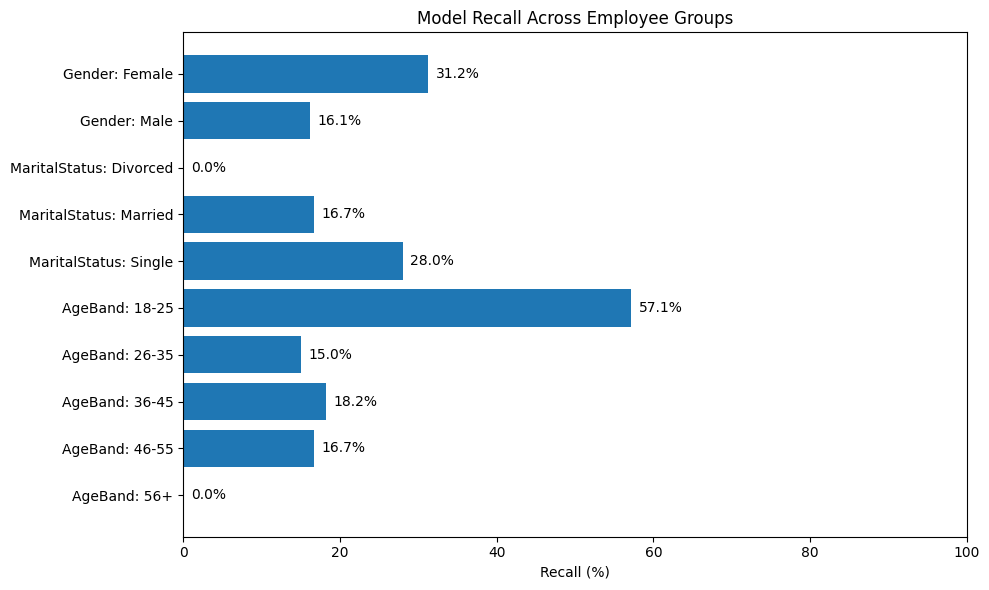

Fairness CSV and chart saved successfully.


In [19]:
import os
import matplotlib.pyplot as plt

# Create outputs folder if it does not exist
outputs_dir = "/content/drive/MyDrive/CSC4110_G09/outputs"
os.makedirs(outputs_dir, exist_ok=True)

# Save fairness table
fairness_table.to_csv(
    os.path.join(outputs_dir, "fairness.csv"),
    index=False
)

# Prepare chart labels
chart_data = fairness_table.dropna(subset=["Recall"]).copy()

labels = (
    chart_data["Group_Type"] + ": " + chart_data["Group"]
)

# Create bar chart
plt.figure(figsize=(10, 6))
bars = plt.barh(labels, chart_data["Recall"] * 100)

plt.xlabel("Recall (%)")
plt.title("Model Recall Across Employee Groups")
plt.xlim(0, 100)
plt.gca().invert_yaxis()

# Add percentage labels
for bar, value in zip(bars, chart_data["Recall"] * 100):
    plt.text(
        value + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.1f}%",
        va="center"
    )

plt.tight_layout()

# Save chart
plt.savefig(
    os.path.join(outputs_dir, "fairness.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Fairness CSV and chart saved successfully.")

In [20]:
# Check feature names for possible personal identifiers
keywords = ["id", "name", "phone", "email"]

flagged = []

print("FEATURE IDENTIFIER AUDIT")
print("-" * 45)

for feature in X.columns:
    is_flagged = any(
        keyword in feature.lower()
        for keyword in keywords
    )

    if is_flagged:
        flagged.append(feature)
        print(f"{feature}: FLAGGED")
    else:
        print(f"{feature}: Not flagged")

print("\nFlagged features:", flagged)

FEATURE IDENTIFIER AUDIT
---------------------------------------------
Age: Not flagged
BusinessTravel: Not flagged
DailyRate: Not flagged
Department: Not flagged
DistanceFromHome: Not flagged
Education: Not flagged
EducationField: Not flagged
EnvironmentSatisfaction: Not flagged
Gender: Not flagged
HourlyRate: Not flagged
JobInvolvement: Not flagged
JobLevel: Not flagged
JobRole: Not flagged
JobSatisfaction: Not flagged
MaritalStatus: Not flagged
MonthlyIncome: Not flagged
MonthlyRate: Not flagged
NumCompaniesWorked: Not flagged
OverTime: Not flagged
PercentSalaryHike: Not flagged
PerformanceRating: Not flagged
RelationshipSatisfaction: Not flagged
StockOptionLevel: Not flagged
TotalWorkingYears: Not flagged
TrainingTimesLastYear: Not flagged
WorkLifeBalance: Not flagged
YearsAtCompany: Not flagged
YearsInCurrentRole: Not flagged
YearsSinceLastPromotion: Not flagged
YearsWithCurrManager: Not flagged

Flagged features: []


In [21]:
# Check numeric feature correlations with Attrition
numeric_data = X_train.select_dtypes(include=["number"]).copy()
numeric_data["Attrition"] = y_train

correlations = numeric_data.corr(numeric_only=True)["Attrition"].drop(
    "Attrition"
)

# Flag correlations above the absolute 0.95 threshold
high_corr = correlations[correlations.abs() > 0.95]

print("FEATURE CORRELATIONS WITH ATTRITION")
print("-" * 45)
print(correlations.sort_values(key=abs, ascending=False).round(4))

print("\nFeatures with absolute correlation above 0.95:")
print(high_corr if not high_corr.empty else "None found.")

FEATURE CORRELATIONS WITH ATTRITION
---------------------------------------------
TotalWorkingYears          -0.1862
Age                        -0.1853
YearsWithCurrManager       -0.1688
YearsInCurrentRole         -0.1670
JobLevel                   -0.1662
MonthlyIncome              -0.1604
YearsAtCompany             -0.1551
StockOptionLevel           -0.1428
JobInvolvement             -0.1251
EnvironmentSatisfaction    -0.1129
JobSatisfaction            -0.1034
DistanceFromHome            0.0867
WorkLifeBalance            -0.0803
DailyRate                  -0.0714
NumCompaniesWorked          0.0486
RelationshipSatisfaction   -0.0434
YearsSinceLastPromotion    -0.0429
TrainingTimesLastYear      -0.0394
Education                  -0.0297
MonthlyRate                 0.0218
HourlyRate                 -0.0194
PercentSalaryHike          -0.0091
PerformanceRating           0.0070
Name: Attrition, dtype: float64

Features with absolute correlation above 0.95:
None found.


In [22]:
# Reload the original dataset for the audit
raw_df = pd.read_csv(data_path)

# Identify constant columns
constant_columns = [
    col for col in raw_df.columns
    if raw_df[col].nunique(dropna=False) <= 1
]

# Check EmployeeNumber
print("EmployeeNumber exists in original dataset:",
      "EmployeeNumber" in raw_df.columns)

print("EmployeeNumber included in model features:",
      "EmployeeNumber" in X.columns)

# Display constant columns
print("\nConstant columns:")
print(constant_columns)

# Check whether constant columns are model features
print("\nConstant columns included in model features:")
print([col for col in constant_columns if col in X.columns])

# Confirm excluded columns
print("\nFinal feature count:", len(X.columns))
print("EmployeeNumber excluded:", "EmployeeNumber" not in X.columns)

EmployeeNumber exists in original dataset: True
EmployeeNumber included in model features: False

Constant columns:
['EmployeeCount', 'Over18', 'StandardHours']

Constant columns included in model features:
[]

Final feature count: 30
EmployeeNumber excluded: True


## Responsible Feature-Use Decisions

### Personal identifiers
No model feature names matched the specified identifier keywords: id, name, phone or email. EmployeeNumber was present in the original dataset but was excluded from model training because it is an employee identifier.

### Constant columns
EmployeeCount, Over18 and StandardHours were constant columns and were excluded from the model features.

### Data leakage
No numeric feature had an absolute correlation above 0.95 with Attrition. This check did not identify obvious numeric leakage, although it does not rule out all forms of leakage.

### Gender and MaritalStatus
Gender and MaritalStatus were included in the current model features, but their use in individual employment predictions raises ethical and fairness concerns. They should be excluded from any production prediction model unless their use is independently justified and legally approved. They may be retained separately for controlled fairness auditing, subject to privacy safeguards.

### Age
Age is also a sensitive employment-related characteristic. It should be reviewed carefully before any operational use. Age bands were used here for fairness auditing.

## Model Card

In [23]:
model_card = """# Model Card – Group G9

## 1. Model Purpose
This model analyses historical employee data to estimate patterns associated with employee attrition. It is intended for research, learning and responsible HR workforce analysis, not automated employment decisions.

## 2. Intended Users
The intended users are authorised HR analysts, data scientists and researchers. Individual risk scores must only be accessible to authorised HR personnel.

## 3. Data Source and Licence
Dataset: IBM HR Analytics Employee Attrition Dataset (WA_Fn-UseC_-HR-Employee-Attrition.csv).

The dataset was obtained from the project data files. Its original source and licence should be verified before redistribution or commercial use.

## 4. Features Used
The model uses 30 features, including Age, Gender, MaritalStatus, JobRole, MonthlyIncome, JobSatisfaction and YearsAtCompany.

EmployeeNumber was excluded because it is an employee identifier. EmployeeCount, Over18 and StandardHours were excluded because they are constant columns.

Gender, MaritalStatus and Age require careful ethical and legal review before any production use.

## 5. Performance on Test Data
The model was evaluated on a stratified hold-out test set containing 294 employees.

- Accuracy: 86.05%
- Precision: 71.43%
- Recall: 21.28%
- F1 Score: 32.79%

The test set contained 47 employees who actually left. The model correctly identified 10 and missed 37.

The low recall indicates that the model misses many actual attrition cases. Accuracy alone should not be used to judge its usefulness.

## 6. Fairness Check Results
Recall was compared across Gender, MaritalStatus and age bands.

- Gender: Female 31.25%; Male 16.13%.
- MaritalStatus: Divorced 0%; Married 16.67%; Single 28%.
- Age: 18–25: 57.14%; 26–35: 15%; 36–45: 18.18%; 46–55: 16.67%; 56+: 0%.

The largest observed gap was across age bands: 57.14 percentage points.

The 56+ group had only 3 actual leavers, so its recall estimate is unstable. These results indicate differences in model performance but do not by themselves prove discrimination.

## 7. Limitations
- The model has low recall for employees who leave.
- The dataset may not represent other organisations, countries or current workforce conditions.
- Small subgroup sample sizes make some fairness estimates unreliable.
- Fairness checks based on recall alone do not establish overall fairness.
- Correlation checks do not rule out every form of data leakage.
- Historical patterns may not remain valid over time.

## 8. Who Should Not Use the Model
The model should not be used by employers to make automated decisions about employees. It should not be used as the sole basis for any employment action.

## 9. Testing Before Release

### Test set used
A stratified 20% hold-out test set containing 294 rows, with random_state=42.

### Proposed release acceptance criteria
Before any controlled pilot, the model should meet these proposed minimum targets:

- Recall for attrition: at least 70%.
- Precision: at least 30%.
- F1 Score: at least 40%.
- Maximum subgroup recall gap: 15 percentage points, subject to adequate subgroup sample sizes.

These are proposed governance thresholds, not achieved model results. The current model does not meet the proposed recall or F1 targets and should not be released for operational use.

### Who pilots the app first
Any future pilot should begin with authorised HR analysts and data-governance reviewers in a controlled shadow-testing environment. Predictions must not influence employment decisions during the pilot.

## 10. Responsible Use Rules
- The model must NEVER be used to dismiss staff.
- The model must NEVER be used to refuse promotion.
- The model must NEVER be used to cut pay.
- Individual risk scores must be visible only to authorised HR personnel.
- Predictions must not replace human judgement or fair employment procedures.
- Any future deployment requires independent fairness, privacy and legal review.
"""
project_dir = "/content/drive/MyDrive/CSC4110_G09"

# Ensure the report folder exists
os.makedirs(os.path.join(project_dir, "report"), exist_ok=True)

model_card_path = os.path.join(
    project_dir, "report", "model_card.md"
)

with open(model_card_path, "w", encoding="utf-8") as file:
    file.write(model_card)

print("Model card saved successfully:")
print(model_card_path)

Model card saved successfully:
/content/drive/MyDrive/CSC4110_G09/report/model_card.md


## Fairness Analysis

The largest observed fairness gap was across age groups, with recall ranging from 0% for employees aged 56+ to 57.14% for those aged 18–25, a difference of 57.14 percentage points. However, the 56+ group had only three actual leavers, making its result unreliable. Gender and marital status also showed differences in recall, indicating that the model does not identify attrition equally across all groups. The organisation should investigate these differences, review sensitive features, collect more representative data and improve the model before considering any deployment.

In [24]:
import os

required_files = [
    "outputs/fairness.csv",
    "outputs/fairness.png",
    "report/model_card.md"
]

print("TASK 9.2 DELIVERABLE CHECK")
print("-" * 40)

for file in required_files:
    path = os.path.join(project_dir, file)
    print(f"{file}: {'SAVED' if os.path.exists(path) else 'MISSING'}")

TASK 9.2 DELIVERABLE CHECK
----------------------------------------
outputs/fairness.csv: SAVED
outputs/fairness.png: SAVED
report/model_card.md: SAVED
